# Our method (FVI + per-point decomposition) vs model-free RL baselines

Three external baselines, all facing the identical environment, constraints and evaluation
episodes:

| baseline | family | how it handles `a in {0,1,2}^m` (3^m = 59049 at m=10) |
|---|---|---|
| **BDQ** | value-based | factors `Q` into `m` branches, so `max_a Q` is `m` independent 3-way argmins ([action-branching-agents](https://github.com/atavakol/action-branching-agents), Tavakoli et al. AAAI 2018, MIT) |
| **TRPO** | policy-gradient | **needs no max at all** — critic is `V(s)`, actor is updated on *sampled* actions; a hard KL trust region keeps each step small |

> **PPO was evaluated and dropped.** With the same swap policy and budget it collapses to
> the null policy whenever `c_edit > 0` (taxed random swaps ⇒ negative advantage ⇒ one large
> unconstrained step into the all-keep optimum, with no gradient out). TRPO's KL bound
> prevents exactly that, so TRPO is kept as the policy-gradient representative. Recorded
> here so the omission is not mistaken for cherry-picking.

**The combinatorial action space, three different ways.** Value-based methods must
bootstrap with `max_a Q(s', a)` — exactly the intractable part; BDQ makes it tractable by
factoring. Policy-gradient methods dissolve the max entirely: their critic is a state value
and their actor never argmaxes. What they need instead is a distribution over `3^m` that
can be *sampled from and scored*.

For TRPO we parameterise that distribution over delete/duplicate **swaps** — the same
coordinates the `balance` constraint is written in:

    r        ~ Categorical(r_logits)                 how many swaps
    del_1..r ~ sequential softmax, no replacement    which points to delete
    dup_1..r ~ sequential softmax, disjoint          which to duplicate

a Plackett-Luce draw, giving feasibility **by construction**, an **exact** log-probability
(so the importance ratio and the KL are unbiased), and `O(m)` sampling from a space of size `3^m`.

> The obvious alternative — an independent 3-way categorical per point, then project onto
> the feasible set — **fails completely** here, and the reason is worth knowing: with
> `balance=True`, flipping one point to "delete" changes nothing until a matching duplicate
> appears, so the projection erases single-coordinate changes and the policy gradient sits
> on a plateau. PPO collapses to the null policy under every entropy/lr setting. See the
> `trpo.py` docstring.

Our method also has two selection tiers, so **five learners** are compared:

| learner | action selection | uses the interaction `B`? |
|---|---|---|
| `first-order` | sort on `α` only | no — `B` is dropped |
| `BDQ` | per-branch argmin + feasibility projection | n/a |
| `TRPO` | swap policy, KL trust region | n/a |

Both method variants are trained **self-consistently** — the tier used at decision time is
also the tier used to collect rollouts — so each one's wall-clock includes the true cost of
its own selector.

---

## Fairness protocol

| axis | control |
|---|---|
| environment | identical `EnvConfig`; identical `theta_star`, `theta_target`, `theta_0` |
| evaluation | identical `eval_seed` + `eval_episodes` → all policies scored on the **same episodes** |
| seeds | same seed list for every learner; mean ± std reported |
| network init | `torch.manual_seed(s)` re-applied before each learner |
| env interactions | `K_iters × N_episodes` episodes each — **matched** |
| replay | BDQ and FVI: off-policy FIFO buffer, same capacity |
| features | TRPO/BDQ share the **identical** feature set (`theta`, `theta−target`, `t`, per-point `phi_i`, `resid_i`) |
| optimiser | Adam, same `weight_decay` |
| checkpointing | `best_checkpoint=True` for all |
| **constraints** | every policy emits actions from the **same feasible set** (asserted in §5) |
| network capacity | *not* matched — the model-free baselines are far larger (**advantages them**) |
| gradient steps | *not* matched for TRPO — see below |
| wall-clock | *not* matched at equal `K_iters` — reported separately in §3 |

Asymmetries left in deliberately, all **in the baselines' favour** or inherent:

1. **The model-free baselines have several times more parameters.** Not handicapped — if
   they still lose, the result is robust to capacity.
2. **TRPO is on-policy**, so each batch is used for a few epochs and discarded; it
   cannot absorb the same gradient-step count as the replay-based learners without
   overfitting their own batch. We therefore match **environment interactions**, the
   standard currency for on-policy vs off-policy comparison, and let gradient steps differ.
3. **`c_edit` is analytic for our method, learned-from-cost for the baselines.** This is not
   a setup flaw; it *is* the hypothesis. Removing it would mean removing the method.

In [33]:
import os, sys
from pathlib import Path
_ROOT = Path.cwd()
if _ROOT.name == "notebooks":        # run from notebooks/: work from the repo root
    _ROOT = _ROOT.parent; os.chdir(_ROOT)
sys.path.insert(0, str(_ROOT / "src"))

import time
from dataclasses import replace

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline

from config import EnvConfig, MethodConfig, TIER_NAME, TIER_MODE
from env import Environment, is_feasible
from value_net import ValueNet
from fvi import train_fvi, evaluate
from agents import NullAgent, GreedyAgent, MethodAgent
from bdq import train_bdq, BDQAgent, BranchQNet
from trpo import train_trpo, TRPOAgent, SwapPolicy, StateValue, max_swaps

# NB: do not `import viz` / `import diagnostics` here -- they call
# matplotlib.use("Agg") at import time, which disables inline plots.

plt.rcParams["figure.dpi"] = 110
plt.rcParams.update({
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Helvetica", "Arial"],
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "0.85",
    "grid.linewidth": 0.6,
    "grid.alpha": 0.6,
})
print("torch", torch.__version__)

torch 2.11.0+cu128


## Configuration

`QUICK = True` → fast smoke run (1 seed, K=20). `QUICK = False` → 3 seeds × K=30.

Approximate per-iteration cost at `m=10`: `first-order` 1.5 s,
`TRPO` 1.4 s, `BDQ` 13.1 s — BDQ dominates the runtime.

> **On `K_COMPARE` and TRPO.** TRPO trades sample efficiency for stability: its hard KL
> bound *guarantees* it cannot collapse, but each step is small, so it converges later than
> the others. At K=20 it is still near null; by K=50 it reaches ≈11.0 — the **strongest**
> baseline here, edging out BDQ. If you report TRPO, run `K_COMPARE >= 50` or you will be
> showing it pre-convergence, which a reviewer will (rightly) flag.

Env/method settings are the ones you have been running: `d=5, m=10, T=10, c_edit=0.1`.

In [34]:
QUICK = False                      # <- set True for a fast smoke run

ECFG = EnvConfig(d=5, m=10, T=10, eta=0.2)
CFG  = MethodConfig(c_edit=0.1, weight_decay=1e-3)

SEEDS      = (0,) if QUICK else (0, 1, 2)
K_COMPARE  = 20 if QUICK else 30           # matched budget for ALL learners
EVAL_EPISODES, EVAL_SEED = 200, 999

LEARNERS = ["first-order", "BDQ", "TRPO"]
NAMES    = ["null", "greedy", "TRPO", "BDQ", "first-order"]
COLORS   = {"null": "#5b5b5b", "greedy": "#eb6834", "TRPO": "#4a3aa7",
            "BDQ": "#e34948", "first-order": "#2a78d6", "exact": "#e87ba4"}
# ours (any selector tier) shares one marker; every baseline gets its own
MARKERS  = {"null": "D", "greedy": "s", "TRPO": "^", "BDQ": "X",
            "first-order": "o", "exact": "o"}
TRPO_ITERS = max(K_COMPARE, 50)   # TRPO converges later than the others -- see note

print(f"seeds={SEEDS}  K_iters={K_COMPARE}  "
      f"episodes/learner={K_COMPARE*CFG.N_episodes}  "
      f"grad steps/learner={K_COMPARE*CFG.n_grad_steps}")

seeds=(0, 1, 2)  K_iters=30  rank_r=2  episodes/learner=1500  grad steps/learner=15000


## Fairness audit: capacity and budget

Note both method tiers share the **same `V̂` architecture** — they differ only in how the
action is chosen from `(α, B)`, so the parameter count is identical.

In [35]:
def count_params(net):
    return sum(p.numel() for p in net.parameters())

_env = Environment(ECFG, CFG)
_v, _q = ValueNet(_env.d, _env.T, CFG.hidden), BranchQNet(_env.d, _env.T, CFG.hidden)
_mr = max_swaps(_env.m, CFG.B)
_tr = count_params(SwapPolicy(_env.d, _env.T, _mr, CFG.hidden)) + \
      count_params(StateValue(_env.d, _env.T, CFG.hidden))   # separate actor + critic

print(f"{'':22}{'first-order':>24}{'BDQ':>12}{'TRPO':>12}")
print(f"{'parameters':22}{count_params(_v):>24,}{count_params(_q):>12,}{_tr:>12,}"
      f"   <- model-free baselines are far larger")
print(f"{'episodes collected':22}{K_COMPARE*CFG.N_episodes:>24,}{K_COMPARE*CFG.N_episodes:>12,}   <- matched")
print(f"{'gradient steps':22}{K_COMPARE*CFG.n_grad_steps:>24,}{K_COMPARE*CFG.n_grad_steps:>12,}   <- matched")
print(f"{'replay capacity':22}{CFG.buffer_capacity:>24,}{CFG.buffer_capacity:>12,}   <- matched")
print(f"{'eval episodes':22}{EVAL_EPISODES:>24,}{EVAL_EPISODES:>12,}   <- identical episodes")

                        first-order / low-rank         BDQ        TRPO
parameters                              17,537     135,940     272,009   <- model-free baselines are far larger
episodes collected                       1,500       1,500   <- matched
gradient steps                          15,000      15,000   <- matched
replay capacity                         20,000      20,000   <- matched
eval episodes                              200         200   <- identical episodes


## Train all three learners

Same seed → same `Environment` → same target and data stream, and `torch.manual_seed(s)`
is re-applied before each learner so they start from the same network initialisation.

In [36]:
def run_seed(s, K):
    """Train first-order, BDQ and TRPO on one seed."""
    cfg_k = replace(CFG, K_iters=K)
    torch.manual_seed(s)
    env = Environment(ECFG, cfg_k)

    hist, times, Vs = {}, {}, {}
    for tier in ["greedy"]:
        cfg_t = replace(cfg_k, select_mode=tier)
        torch.manual_seed(s)                       # identical init across learners
        t0 = time.perf_counter()
        V, h = train_fvi(env, cfg_t, seed=s, verbose=False, return_history=True,
                         best_checkpoint=True, eval_episodes=EVAL_EPISODES,
                         eval_seed=EVAL_SEED)
        times[TIER_NAME[tier]] = time.perf_counter() - t0
        hist[TIER_NAME[tier]] = h
        Vs[tier] = V

    torch.manual_seed(s)
    t0 = time.perf_counter()
    net, h_b = train_bdq(env, cfg_k, seed=s, verbose=False, return_history=True,
                         best_checkpoint=True, eval_episodes=EVAL_EPISODES,
                         eval_seed=EVAL_SEED)
    times["BDQ"] = time.perf_counter() - t0
    hist["BDQ"] = h_b

    torch.manual_seed(s)
    t0 = time.perf_counter()
    tnet, h_t = train_trpo(env, replace(cfg_k, K_iters=TRPO_ITERS), seed=s, verbose=False,
                           return_history=True, best_checkpoint=True,
                           eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
    times["TRPO"] = time.perf_counter() - t0
    hist["TRPO"] = h_t[:K]        # trim to the shared axis for the learning-curve plots

    agents = {
        "null":   NullAgent(),
        "greedy": GreedyAgent(env.victim, env.theta_target, cfg_k, mode="greedy"),
        "BDQ":    BDQAgent(net, env, cfg_k, torch.Generator().manual_seed(s + 1)),
        "TRPO":   TRPOAgent(tnet, env, cfg_k, torch.Generator().manual_seed(s + 1),
                            deterministic=True),
    }
    for tier in ["greedy"]:
        agents[TIER_NAME[tier]] = MethodAgent(
            Vs[tier], env.victim, env.theta_target,
            replace(cfg_k, select_mode=tier), torch.Generator().manual_seed(s + 1))

    costs = {n: evaluate(env, a, torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES)
             for n, a in agents.items()}
    return {"env": env, "agents": agents, "costs": costs, "hist": hist,
            "times": times, "V_sort": Vs["greedy"], "cfg": cfg_k}


runs = []
for s in SEEDS:
    t0 = time.perf_counter()
    r = run_seed(s, K_COMPARE)
    runs.append(r)
    c, tm = r["costs"], r["times"]
    print(f"seed {s}: first-order={c['first-order']:6.3f} ({tm['first-order']:5.1f}s)  "
          f"BDQ={c['BDQ']:6.3f} ({tm['BDQ']:6.1f}s)  "
          f"TRPO={c['TRPO']:6.3f} ({tm['TRPO']:5.1f}s)  "
          f"greedy={c['greedy']:6.3f}  null={c['null']:6.3f}   [{time.perf_counter()-t0:.0f}s]")

seed 0: first-order= 8.622 ( 24.9s)  low-rank= 8.503 (137.4s)  BDQ=10.840 ( 408.8s)  TRPO=11.036 (104.8s)  greedy=15.999  null=16.431   [683s]
seed 1: first-order= 8.441 ( 36.4s)  low-rank= 8.401 (185.9s)  BDQ=10.051 ( 409.1s)  TRPO= 9.612 (124.7s)  greedy=15.999  null=16.431   [764s]
seed 2: first-order= 8.492 ( 37.6s)  low-rank= 8.437 (182.8s)  BDQ=11.631 ( 355.8s)  TRPO= 9.898 (117.1s)  greedy=15.999  null=16.431   [701s]


## 1. Headline: mean episode cost

Lower is better. Error bars are ±1 std over seeds.

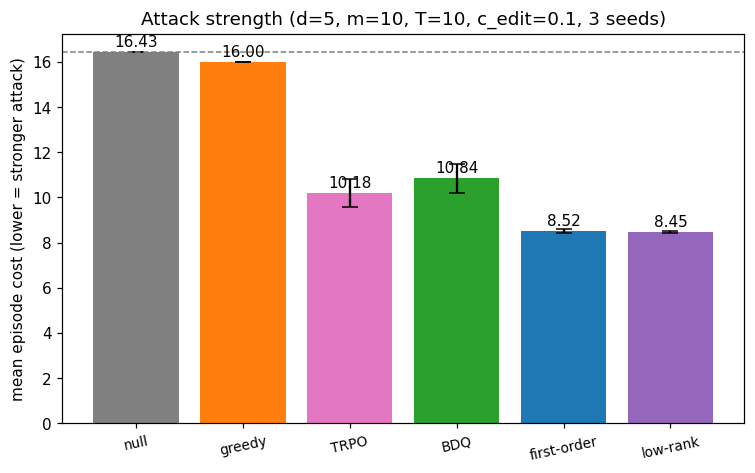

greedy             vs null:   2.6%   vs BDQ:  -47.6%
BDQ                vs null:  34.0%   vs BDQ:    0.0%
first-order        vs null:  48.2%   vs BDQ:   21.4%
low-rank           vs null:  48.6%   vs BDQ:   22.1%

low-rank - first-order = -0.071  (+0.84% improvement from using B)


In [26]:
cost_mean = {n: float(np.mean([r["costs"][n] for r in runs])) for n in NAMES}
cost_std  = {n: float(np.std ([r["costs"][n] for r in runs])) for n in NAMES}

fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.bar(range(len(NAMES)), [cost_mean[n] for n in NAMES],
              yerr=[cost_std[n] for n in NAMES], capsize=5,
              color=[COLORS[n] for n in NAMES])
for i, n in enumerate(NAMES):
    ax.text(i, cost_mean[n] + 0.25, f"{cost_mean[n]:.2f}", ha="center", fontsize=10)
ax.axhline(cost_mean["null"], color=COLORS["null"], ls="--", lw=1)
ax.set_xticks(range(len(NAMES)))
ax.set_xticklabels(NAMES, rotation=12, fontsize=9)
ax.set_ylabel("mean episode cost (lower = stronger attack)")
ax.set_title(f"Attack strength (d={ECFG.d}, m={ECFG.m}, T={ECFG.T}, "
             f"c_edit={CFG.c_edit}, {len(SEEDS)} seeds)")
plt.show()

nul = cost_mean["null"]
for n in ["greedy", "BDQ", "first-order"]:
    print(f"{n:18} vs null: {(nul-cost_mean[n])/nul*100:5.1f}%   "
          f"vs BDQ: {(cost_mean['BDQ']-cost_mean[n])/cost_mean['BDQ']*100:6.1f}%")

## 2. Learning curves — matched iterations

All three learners see the same number of episodes and take the same number of gradient
steps at each x-value. The top axis converts iterations to **environment transitions**,
the currency that matters when interaction is the expensive resource.

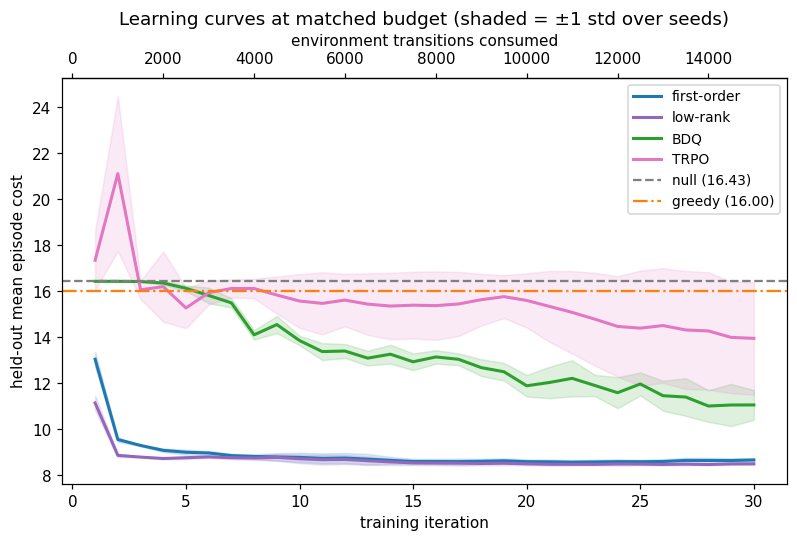

In [27]:
def curve_stats(name):
    H = np.array([r["hist"][name] for r in runs])      # (seeds, K)
    return H.mean(0), H.std(0)

it = np.arange(1, K_COMPARE + 1)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for name in LEARNERS:
    mu, sd = curve_stats(name)
    ax.plot(it, mu, f"{MARKERS[name]}-", color=COLORS[name], lw=2, label=name,
            markevery=max(1, K_COMPARE // 8))
    ax.fill_between(it, mu - sd, mu + sd, color=COLORS[name], alpha=0.15)
ax.axhline(cost_mean["null"],   color=COLORS["null"], ls="--", lw=1.5, label=f"null ({cost_mean['null']:.2f})")
ax.axhline(cost_mean["greedy"], color=COLORS["greedy"], ls="-.", lw=1.5, label=f"greedy ({cost_mean['greedy']:.2f})")
ax.set_xlabel("training iteration")
ax.set_ylabel("held-out mean episode cost")
ax.set_title("Learning curves at matched budget (shaded = ±1 std over seeds)")
ax.legend(fontsize=9)
sec = ax.secondary_xaxis("top", functions=(lambda k: k*CFG.N_episodes*ECFG.T,
                                           lambda n: n/(CFG.N_episodes*ECFG.T)))
sec.set_xlabel("environment transitions consumed")
plt.show()

## 3. Learning curves — matched **wall-clock**

Matched iterations is not matched compute. Re-plotting against cumulative wall-clock
answers *"given a fixed compute budget, which is ahead?"*

(Per-iteration time is `total / K_iters`; all learners run the same held-out evaluation
each iteration, so the approximation is symmetric. Wall-clock is machine-load sensitive —
treat ratios, not absolutes, as the result.)

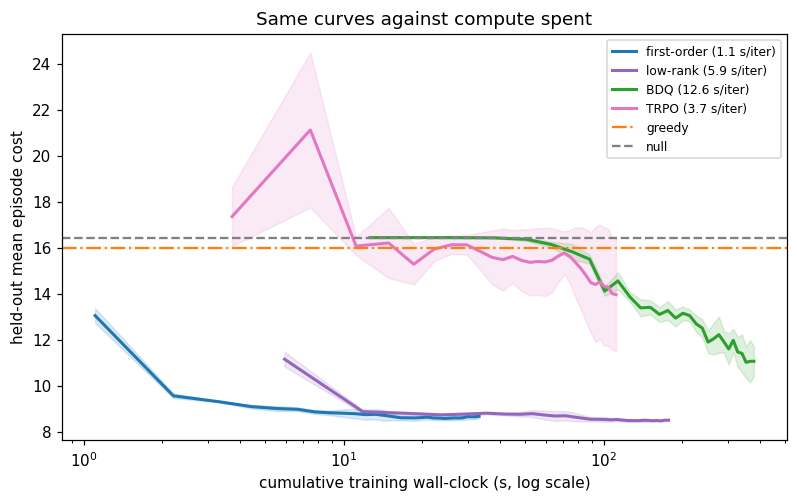

seconds to first reach a cost level:
  cost <= 14.00 :  first-order=     1.1s  low-rank=     5.9s  BDQ=   126.2s  TRPO=   108.0s
  cost <= 12.00 :  first-order=     2.2s  low-rank=     5.9s  BDQ=   252.4s  TRPO=    never
  cost <= 11.06 :  first-order=     2.2s  low-rank=    11.9s  BDQ=   353.4s  TRPO=    never
  cost <= 10.00 :  first-order=     2.2s  low-rank=    11.9s  BDQ=    never  TRPO=    never
  cost <=  9.00 :  first-order=     6.6s  low-rank=    11.9s  BDQ=    never  TRPO=    never


In [28]:
per_it = {n: float(np.mean([r["times"][n] for r in runs])) / K_COMPARE for n in LEARNERS}

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for name in LEARNERS:
    mu, sd = curve_stats(name)
    x = it * per_it[name]
    ax.plot(x, mu, f"{MARKERS[name]}-", color=COLORS[name], lw=2,
            label=f"{name} ({per_it[name]:.1f} s/iter)", markevery=max(1, K_COMPARE // 8))
    ax.fill_between(x, mu - sd, mu + sd, color=COLORS[name], alpha=0.15)
ax.axhline(cost_mean["greedy"], color=COLORS["greedy"], ls="-.", lw=1.5, label="greedy")
ax.axhline(cost_mean["null"],   color=COLORS["null"], ls="--", lw=1.5, label="null")
ax.set_xscale("log")
ax.set_xlabel("cumulative training wall-clock (s, log scale)")
ax.set_ylabel("held-out mean episode cost")
ax.set_title("Same curves against compute spent")
ax.legend(fontsize=8)
plt.show()

# iso-performance: seconds needed to first reach a given cost level
def first_time(hist, x, level):
    for h, xx in zip(hist, x):
        if h <= level:
            return xx
    return None

print("seconds to first reach a cost level:")
bdq_final = curve_stats("BDQ")[0][-1]
for lvl in [14.0, 12.0, bdq_final, 10.0, 9.0]:
    row = f"  cost <= {lvl:5.2f} :"
    for name in LEARNERS:
        t = first_time(curve_stats(name)[0], it * per_it[name], lvl)
        row += f"  {name}={'%7.1fs' % t if t else '  never':>9}"
    print(row)

## 4. Computational cost

Three costs that do **not** point the same way:

- **Training time** — one-off.
- **Decision latency** — paid at every attack step; what matters at deployment.
- **Which stage dominates** — our tiers are decision-bound, BDQ is gradient-step-bound.

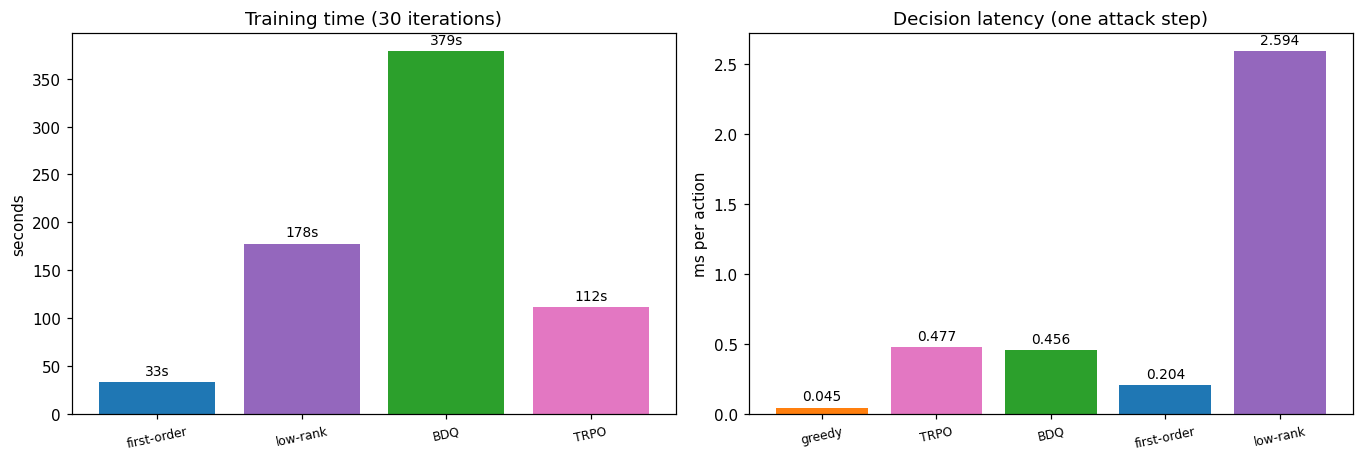

training  : low-rank/first-order = 5.4x   BDQ/first-order = 11.4x   BDQ/low-rank = 2.1x
decision  : low-rank/first-order = 12.7x   low-rank/BDQ = 5.7x


In [29]:
def decision_latency_ms(env, agent, n=200, seed=1):
    rng = torch.Generator().manual_seed(seed)
    theta, z = env.theta_0.clone(), env.stream.sample_batch(env.m, rng)
    agent.act(theta, z, 0)                                   # warm-up
    t0 = time.perf_counter()
    for k in range(n):
        agent.act(theta, z, k % env.T)
    return (time.perf_counter() - t0) / n * 1e3

lat = {n: float(np.mean([decision_latency_ms(r["env"], r["agents"][n]) for r in runs]))
       for n in ["greedy", "TRPO", "BDQ", "first-order"]}
train_t = {n: float(np.mean([r["times"][n] for r in runs])) for n in LEARNERS}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
a1.bar(range(len(train_t)), list(train_t.values()),
       color=[COLORS[k] for k in train_t])
a1.set_xticks(range(len(train_t))); a1.set_xticklabels(list(train_t), rotation=12, fontsize=8)
for i, v in enumerate(train_t.values()):
    a1.text(i, v + max(train_t.values())*0.02, f"{v:.0f}s", ha="center", fontsize=9)
a1.set_ylabel("seconds"); a1.set_title(f"Training time ({K_COMPARE} iterations)")

a2.bar(range(len(lat)), list(lat.values()), color=[COLORS[k] for k in lat])
a2.set_xticks(range(len(lat))); a2.set_xticklabels(list(lat), rotation=12, fontsize=8)
for i, v in enumerate(lat.values()):
    a2.text(i, v + max(lat.values())*0.02, f"{v:.3f}", ha="center", fontsize=9)
a2.set_ylabel("ms per action"); a2.set_title("Decision latency (one attack step)")
plt.tight_layout(); plt.show()

print(f"training  : BDQ/first-order = {train_t['BDQ']/train_t['first-order']:.1f}x   "
      f"TRPO/first-order = {train_t['TRPO']/train_t['first-order']:.1f}x")
print(f"decision  : BDQ/first-order = {lat['BDQ']/lat['first-order']:.1f}x   "
      f"TRPO/first-order = {lat['TRPO']/lat['first-order']:.1f}x")

## 5. Behaviour: what do the policies actually *do*?

- **edits/step** `Σ|a_i−1|` — how aggressively each policy curates, given every edit is
  taxed by `c_edit`.
- **target gap** `‖θ_t − θ̃‖` — how close the victim is driven to the attacker's target.

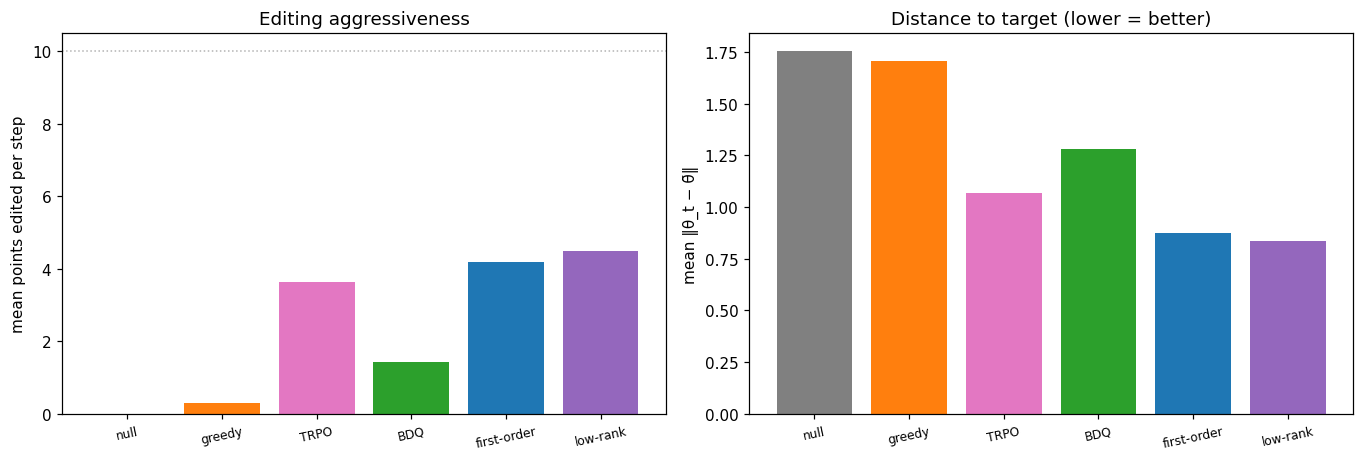

feasibility check: {'null': 'OK', 'greedy': 'OK', 'TRPO': 'OK', 'BDQ': 'OK', 'first-order': 'OK', 'low-rank': 'OK'}


In [37]:
def behaviour(env, agent, n_episodes=100, seed=EVAL_SEED):
    rng = torch.Generator().manual_seed(seed)
    edits = gap = 0.0
    steps, feasible = 0, True
    for _ in range(n_episodes):
        theta = env.theta_0.clone()
        for t in range(env.T):
            z = env.stream.sample_batch(env.m, rng)
            a = agent.act(theta, z, t)
            feasible &= is_feasible(a, CFG.balance, CFG.B, CFG.L)
            edits += float(np.abs(a.numpy() - 1).sum())
            theta = env.victim.update(theta, z, a).detach()
            gap += float((theta - env.theta_target).norm())
            steps += 1
    return edits/steps, gap/steps, feasible

beh = {n: np.mean([behaviour(r["env"], r["agents"][n])[:2] for r in runs], axis=0)
       for n in NAMES}
feas = {n: all(behaviour(r["env"], r["agents"][n], 20)[2] for r in runs) for n in NAMES}
    
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
for ax, k, lab, ttl in [(a1, 0, "mean points edited per step", "Editing aggressiveness"),
                        (a2, 1, "mean ‖θ_t − θ̃‖", "Distance to target (lower = better)")]:
    ax.bar(range(len(NAMES)), [beh[n][k] for n in NAMES], color=[COLORS[n] for n in NAMES])
    ax.set_xticks(range(len(NAMES))); ax.set_xticklabels(NAMES, rotation=12, fontsize=8)
    ax.set_ylabel(lab); ax.set_title(ttl)
a1.axhline(ECFG.m, color="0.7", ls=":", lw=1)
plt.tight_layout(); plt.show()

print("feasibility check:", {n: ("OK" if v else "VIOLATED") for n, v in feas.items()})

## 5c. Equal-budget comparison — who spends a *fixed* budget best?  *(heavy)*

§5 shows our method editing ~4 points/step against BDQ's ~1.1 and greedy's ~0.3. That is
**not** an accounting unfairness — every policy pays the same `c_edit` per edit and that
charge is already inside the reported cost, so greedy and BDQ *chose* to edit less. But it
does mean §1 conflates two different abilities:

1. **willingness** — judging that editing is worth its price at all, and
2. **selectivity** — given a fixed number of edits, picking the *right* points.

This section isolates (2) by removing (1). Two changes:

- **`B = 2k`** — a hard cap. With `balance=True` that means exactly `k` deletes and `k`
  duplicates, so **`2k` points touched per step**.
- **`c_edit = 0`** — the budget becomes a pure *constraint* rather than a *price*. Leaving
  `c_edit > 0` would let policies spend below the cap, and budgets would stay unequal.

The optimal policy depends on the constraint, so **every learner is retrained per budget**.

The third panel is the fairness check: it verifies the budget actually binds. A curve below
the dotted line means that policy under-spent, and the comparison at that point is *still*
not equal-budget.

**All four learners** are retrained at every budget: `first-order`,
`BDQ` and `TRPO`, plus the training-free `null` / `greedy`. Runtime ≈ 10 min per budget
(~40 min total), dominated by BDQ and TRPO.

In [ ]:
RUN_EQUAL_BUDGET = True         # ~40 min: every learner retrained at every budget
BUDGETS = [1, 2, 3, 5]          # k swaps; B = 2k = ||a-1||_1 per step
EB_LEARNERS = ["first-order", "BDQ", "TRPO"]

if RUN_EQUAL_BUDGET:
    eb_names = ["null", "greedy"] + EB_LEARNERS
    eb = {n: {"cost": [], "edits": [], "gap": []} for n in eb_names}
    s0 = SEEDS[0]

    for k in BUDGETS:
        cfg_k = replace(CFG, c_edit=0.0, B=2*k, K_iters=K_COMPARE)
        torch.manual_seed(s0)
        env_k = Environment(ECFG, cfg_k)
        ags = {"null": NullAgent(),
               "greedy": GreedyAgent(env_k.victim, env_k.theta_target,
                                     replace(cfg_k, select_mode="greedy"), mode="greedy")}
        for name in EB_LEARNERS:
            torch.manual_seed(s0)
            if name == "BDQ":
                net = train_bdq(env_k, cfg_k, seed=s0, verbose=False, best_checkpoint=True,
                                eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
                ags[name] = BDQAgent(net, env_k, cfg_k,
                                     torch.Generator().manual_seed(s0 + 1))
            elif name == "TRPO":
                cfg_t = replace(cfg_k, K_iters=TRPO_ITERS)
                net = train_trpo(env_k, cfg_t, seed=s0, verbose=False, best_checkpoint=True,
                                 eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
                ags[name] = TRPOAgent(net, env_k, cfg_t,
                                      torch.Generator().manual_seed(s0 + 1))
            else:
                tier = TIER_MODE[name]
                cfg_t = replace(cfg_k, select_mode=tier)
                V_k = train_fvi(env_k, cfg_t, seed=s0, verbose=False, best_checkpoint=True,
                                eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
                ags[name] = MethodAgent(V_k, env_k.victim, env_k.theta_target, cfg_t,
                                        torch.Generator().manual_seed(s0 + 1))

        line = f"B={2*k} (budget {2*k} pts/step):"
        for n in eb_names:
            c_ = evaluate(env_k, ags[n], torch.Generator().manual_seed(EVAL_SEED),
                          EVAL_EPISODES)
            e_, g_, _ = behaviour(env_k, ags[n], n_episodes=60)
            eb[n]["cost"].append(c_); eb[n]["edits"].append(e_); eb[n]["gap"].append(g_)
            line += f"  {n}: {c_:6.3f} (used {e_:4.2f})"
        print(line, flush=True)

    xb = [2 * k for k in BUDGETS]
    fig, (b1, b2, b3) = plt.subplots(1, 3, figsize=(16, 4.4))
    for n in eb_names:
        b1.plot(xb, eb[n]["cost"], f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
        b2.plot(xb, eb[n]["gap"], f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
        if n != "null":
            b3.plot(xb, eb[n]["edits"], f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
    b3.plot(xb, xb, "k:", lw=1.5, label="budget cap (B)")
    b1.set_xlabel("attack budget (points edited per step)")
    b1.set_ylabel("mean episode cost"); b1.set_title("Cost at equal budget (c_edit=0)")
    b2.set_xlabel("attack budget"); b2.set_ylabel("mean ‖θ_t − θ̃‖")
    b2.set_title("Distance to target at equal budget")
    b3.set_xlabel("budget allowed"); b3.set_ylabel("budget actually used")
    b3.set_title("Fairness check: does the budget bind?")
    for ax in (b1, b2, b3):
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    print("\nadvantage over the best baseline at each budget:")
    ours = [n for n in EB_LEARNERS if n in TIER_MODE]
    base = [n for n in EB_LEARNERS if n not in TIER_MODE]
    for i, k in enumerate(BUDGETS):
        mt = min(ours, key=lambda n: eb[n]["cost"][i])
        ms = eb[mt]["cost"][i]
        bb = min(eb[n]["cost"][i] for n in base)
        best = min(base, key=lambda n: eb[n]["cost"][i])
        print(f"  budget {2*k:2d} pts: ours ({mt}) {ms:6.3f}   best baseline ({best}) {bb:6.3f}"
              f"   -> {(bb-ms)/bb*100:+5.1f}%")
else:
    print("skipped — set RUN_EQUAL_BUDGET = True to run")

## 6. Scaling in `m` — BDQ's home turf  *(heavy: set `RUN_SCALING = True`)*

BDQ exists because the joint action space grows as `3^m`. Our `greedy` tier is `O(m log m)`
on `α` with an `m`-independent network evaluation, so it should be untroubled.

**Note on `c_edit`.** Per-point influence scales as `φ_i ∝ 1/m` (the victim averages the
batch), so at fixed `c_edit` a larger `m` makes *every* edit less profitable and drives all
policies toward null — that would swamp the algorithmic comparison. `SCALE_CEDIT = True`
holds `c_edit·m` constant so each edit stays equally affordable, isolating the algorithms.

In [ ]:
RUN_SCALING  = False         # <- set True to run (several minutes per m)
SCALE_CEDIT  = True          # hold c_edit*m constant (see note above)
MS = [4, 8, 12, 16]

if RUN_SCALING:
    sc = {"m": MS, "null": [], "greedy": [], "BDQ": [],
          "first-order": [], "t": {n: [] for n in LEARNERS}}
    for m in MS:
        ce = CFG.c_edit * ECFG.m / m if SCALE_CEDIT else CFG.c_edit
        ecfg_m = replace(ECFG, m=m)
        cfg_m = replace(CFG, K_iters=20, c_edit=ce)
        torch.manual_seed(0)
        env_m = Environment(ecfg_m, cfg_m)
        ags = {"null": NullAgent(),
               "greedy": GreedyAgent(env_m.victim, env_m.theta_target, cfg_m, mode="greedy")}
        for tier in ["greedy"]:
            cfg_t = replace(cfg_m, select_mode=tier)
            torch.manual_seed(0)
            t0 = time.perf_counter()
            Vm = train_fvi(env_m, cfg_t, seed=0, verbose=False, best_checkpoint=True,
                           eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
            sc["t"][TIER_NAME[tier]].append(time.perf_counter() - t0)
            ags[TIER_NAME[tier]] = MethodAgent(Vm, env_m.victim, env_m.theta_target,
                                              cfg_t, torch.Generator().manual_seed(1))
        torch.manual_seed(0)
        t0 = time.perf_counter()
        Qm = train_bdq(env_m, cfg_m, seed=0, verbose=False, best_checkpoint=True,
                       eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
        sc["t"]["BDQ"].append(time.perf_counter() - t0)
        ags["BDQ"] = BDQAgent(Qm, env_m, cfg_m, torch.Generator().manual_seed(1))

        for n in NAMES:
            sc[n].append(evaluate(env_m, ags[n], torch.Generator().manual_seed(EVAL_SEED),
                                  EVAL_EPISODES))
        print(f"m={m:2d} (3^m={3**m:,}, c_edit={ce:.3f}): " +
              "  ".join(f"{n}={sc[n][-1]:.2f}" for n in NAMES))

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
    for n in NAMES:
        a1.plot(sc["m"], np.array(sc[n])/np.array(sc["null"]), f"{MARKERS[n]}-",
                color=COLORS[n], lw=2, label=n)
    a1.axhline(1.0, color="0.7", ls=":", lw=1)
    a1.set_xlabel("batch size m  (action space = 3^m)"); a1.set_ylabel("cost / null")
    a1.set_title("Attack strength vs m (normalised)"); a1.set_xticks(MS); a1.legend(fontsize=8)
    for n in LEARNERS:
        a2.plot(sc["m"], sc["t"][n], f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
    a2.set_xlabel("batch size m"); a2.set_ylabel("training seconds"); a2.set_yscale("log")
    a2.set_title("Training cost vs m"); a2.set_xticks(MS); a2.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("skipped — set RUN_SCALING = True to run")

## 7. Sensitivity analysis  *(heavy — all flags default to `False`)*

Everything above is one point in configuration space. This section sweeps the axes that
either **carry the claim** or **bound its scope**, with the same fairness protocol as §1:
every learner is retrained at every point, all policies are scored on the identical
held-out episodes, and feasibility is asserted throughout.

| § | axis | why it matters | points × seeds | ≈ runtime |
|---|---|---|---|---|
| 7a | `c_edit` | **the** axis — `c_edit` is what demands per-point credit resolution | 6 × 3 | ~3.2 h |
| 7b | `m` | separates action-space growth from edit economics | 5 × 2 × 1 | ~1.8 h |
| 7c | `T` | isolates what the learned cost-to-go buys over myopic greedy | 6 × 1 | ~1.1 h |
| 7d | linearity violation | converts the §8 caveat into a measured bound | 10 × 1 | ~1.8 h |

Budget ≈ `points × seeds × 11 min` at `K_COMPARE=30`; BDQ is ~60% of it.

**Run §1–§5 first.** This section reuses `behaviour` (§5), `decision_latency_ms` (§4)
and `runs` (§1).

**Not swept, deliberately:** `λ` is redundant with `c_edit`. The objective is
`c_edit·Σ|aᵢ−1| + (λ/2)‖θ′−θ̃‖²`, so `(λ, c_edit) → (cλ, c·c_edit)` multiplies `Q` by `c`
and leaves the argmin unchanged — only the ratio moves the policy. `d`, `B` and
`weight_decay` have their own sweeps in `viz.py`; `B` is also §5c.

In [20]:
# --- shared sweep machinery -------------------------------------------------
RUN_CEDIT     = True    # 7a  ~3.2 h
RUN_M_SENS    = True    # 7b  ~1.8 h
RUN_T_SENS    = True     # 7c  ~1.1 h
RUN_VIOLATION = True    # 7d  ~1.8 h

SWEEP_LEARNERS = ["first-order", "BDQ", "TRPO"]               # retrained per point
SWEEP_FREE     = ["null", "greedy"]                           # training-free


def build_agents(env, cfg, seed, learners=SWEEP_LEARNERS):
    """Train `learners` on this env/cfg; return {name: agent} incl. the free baselines."""
    ags = {"null": NullAgent(),
           "greedy": GreedyAgent(env.victim, env.theta_target,
                                 replace(cfg, select_mode="greedy"), mode="greedy")}
    for name in learners:
        torch.manual_seed(seed)                       # identical init across learners
        if name == "BDQ":
            net = train_bdq(env, cfg, seed=seed, verbose=False, best_checkpoint=True,
                            eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
            ags[name] = BDQAgent(net, env, cfg, torch.Generator().manual_seed(seed + 1))
        elif name == "TRPO":
            cfg_t = replace(cfg, K_iters=max(cfg.K_iters, TRPO_ITERS))
            net = train_trpo(env, cfg_t, seed=seed, verbose=False, best_checkpoint=True,
                             eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
            ags[name] = TRPOAgent(net, env, cfg_t, torch.Generator().manual_seed(seed + 1),
                                  deterministic=True)
        else:
            cfg_t = replace(cfg, select_mode=TIER_MODE[name])
            V = train_fvi(env, cfg_t, seed=seed, verbose=False, best_checkpoint=True,
                          eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
            ags[name] = MethodAgent(V, env.victim, env.theta_target, cfg_t,
                                    torch.Generator().manual_seed(seed + 1))
    return ags


def sweep(values, make_cfgs, seeds=(0,), learners=SWEEP_LEARNERS, label="x",
          post_env=None, n_beh=40):
    """1-D sweep: retrain every learner at every point, score on the shared episodes.

    make_cfgs(v) -> (EnvConfig, MethodConfig) for axis value v.
    post_env(env, v) may mutate the freshly built Environment (used by 7d).
    Returns {name: {"cost", "cost_sd", "edits"}}, each a list over `values`.
    """
    names = SWEEP_FREE + list(learners)
    res = {n: {"cost": [], "cost_sd": [], "edits": []} for n in names}
    for v in values:
        ecfg_v, cfg_v = make_cfgs(v)
        per_c = {n: [] for n in names}
        per_e = {n: [] for n in names}
        for s in seeds:
            torch.manual_seed(s)
            env_v = Environment(ecfg_v, cfg_v)
            if post_env is not None:
                post_env(env_v, v)
            ags = build_agents(env_v, cfg_v, s, learners)
            for n in names:
                per_c[n].append(evaluate(env_v, ags[n],
                                torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES))
                e_, _, ok = behaviour(env_v, ags[n], n_episodes=n_beh)
                assert ok, f"{n} emitted an infeasible action at {label}={v}"
                per_e[n].append(e_)
        for n in names:
            res[n]["cost"].append(float(np.mean(per_c[n])))
            res[n]["cost_sd"].append(float(np.std(per_c[n])))
            res[n]["edits"].append(float(np.mean(per_e[n])))
        print(f"  {label}={v}: " +
              "  ".join(f"{n}={res[n]['cost'][-1]:.2f}" for n in names), flush=True)
    return res


def plot_sweep(xs, res, xlabel, title, panel2="edits", xticks=None):
    """Left: cost/null. Right: edits/step ('edits') or planning premium ('premium')."""
    names = list(res)
    nul = np.array(res["null"]["cost"])
    fig, (p1, p2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
    for n in names:
        p1.plot(xs, np.array(res[n]["cost"]) / nul, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
    p1.axhline(1.0, color="0.7", ls=":", lw=1)
    p1.set_xlabel(xlabel); p1.set_ylabel("cost / null  (lower = stronger attack)")
    p1.set_title(title); p1.legend(fontsize=8)

    if panel2 == "premium":
        g = np.array(res["greedy"]["cost"])
        for n in ["first-order"]:
            if n in res:
                p2.plot(xs, (g - np.array(res[n]["cost"])) / g * 100, f"{MARKERS[n]}-",
                        color=COLORS[n], lw=2, label=f"{n} vs greedy")
        p2.axhline(0, color="k", lw=0.8)
        p2.set_ylabel("cost reduction vs greedy (%)")
        p2.set_title("Planning premium — what the learned V̂ buys")
    else:
        for n in names:
            if n != "null":
                p2.plot(xs, res[n]["edits"], f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
        p2.set_ylabel("mean points edited per step")
        p2.set_title("Willingness to pay for edits")
    p2.set_xlabel(xlabel); p2.legend(fontsize=8)
    for p in (p1, p2):
        if xticks is not None:
            p.set_xticks(xticks)
    plt.tight_layout(); plt.show()


print("sweep helpers ready — flags:",
      {"7a": RUN_CEDIT, "7b": RUN_M_SENS, "7c": RUN_T_SENS,
       "7d": RUN_VIOLATION})

sweep helpers ready — flags: {'7a': True, '7b': True, '7c': True, '7d': True, '7e': True}


### 7a. Edit price `c_edit` — the credit-resolution axis

The hypothesis in §8 is that the methods order by how finely they can attribute cost to
individual points: TRPO gets **one scalar** advantage for the whole joint action, BDQ gets
**per-branch** Q-values, ours gets a **per-point analytic `αᵢ`**. `c_edit` is exactly the
knob that demands that discrimination — at `c_edit=0` every edit is free and crude
policies do fine; as the price rises you must know *which* points are worth buying.

So each policy should fall off toward null at the `c_edit` where its credit resolution
runs out, **in that order**. The right panel is the mechanism: cost degrades because the
policy stops editing.

`c_edit=0` is included as the anchor where the axis should *not* discriminate.

In [39]:
CEDITS      = [0.4, 0.0, 0.025, 0.05, 0.1, 0.2]
CEDIT_SEEDS = SEEDS         # headline axis -- worth the 3 seeds

if RUN_CEDIT:
    res_ce = sweep(CEDITS,
                   lambda v: (ECFG, replace(CFG, c_edit=v, K_iters=K_COMPARE)),
                   seeds=CEDIT_SEEDS, label="c_edit")
    plot_sweep(CEDITS, res_ce, "edit price  c_edit",
               f"Attack strength vs edit price ({len(CEDIT_SEEDS)} seeds)",
               xticks=CEDITS)

    # where does each policy give up? first c_edit at which it is within 5% of null
    print("\ncollapse point (first c_edit with cost/null > 0.95):")
    nul = np.array(res_ce["null"]["cost"])
    for n in SWEEP_FREE[1:] + SWEEP_LEARNERS:
        r = np.array(res_ce[n]["cost"]) / nul
        hit = [c for c, v in zip(CEDITS, r) if v > 0.95]
        print(f"  {n:12} {'c_edit = ' + str(hit[0]) if hit else 'survives the whole sweep':30}"
              f"  (cost/null at c_edit={CEDITS[-1]}: {r[-1]:.3f})")
else:
    print("skipped — set RUN_CEDIT = True")

RuntimeError: One of the differentiated Tensors appears to not have been used in the graph. Set allow_unused=True if this is the desired behavior.

### 7b. Batch size `m` — action-space growth vs edit economics

Two confounded effects grow with `m`, and this is the plot that separates them:

1. the joint action space grows as `3^m` — the reason BDQ exists;
2. per-point influence shrinks as `φᵢ ∝ 1/m` (the victim averages the batch), so at
   **fixed** `c_edit` every edit becomes less profitable and *all* policies drift to null.

Effect 2 is economics, not combinatorics, and it will masquerade as "the method breaks at
large `m`" if you only plot the left panel. Holding `c_edit·m` constant (right panel)
neutralises it — this is the measured `mean|α|·m ≈ 0.275` constant from §5b.

Read the two panels together: any degradation that survives on the **right** is a genuine
scaling limit; degradation that appears only on the **left** is the edit price rising in
disguise.

In [ ]:
MS_SENS = [4, 6, 8, 10, 14]

if RUN_M_SENS:
    res_m = {}
    for scaled in (False, True):
        tag = "c_edit*m held constant" if scaled else "c_edit fixed"
        print(f"[{tag}]")
        res_m[scaled] = sweep(
            MS_SENS,
            lambda m, sc=scaled: (replace(ECFG, m=m),
                                  replace(CFG, K_iters=K_COMPARE,
                                          c_edit=CFG.c_edit * ECFG.m / m if sc
                                          else CFG.c_edit)),
            seeds=(SEEDS[0],), label="m")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
    for ax, scaled, ttl in [(axes[0], False, f"c_edit fixed at {CFG.c_edit}"),
                            (axes[1], True, f"c_edit·m held at {CFG.c_edit*ECFG.m:.1f}")]:
        r = res_m[scaled]
        nul = np.array(r["null"]["cost"])
        for n in r:
            ax.plot(MS_SENS, np.array(r[n]["cost"]) / nul, f"{MARKERS[n]}-",
                    color=COLORS[n], lw=2, label=n)
        ax.axhline(1.0, color="0.7", ls=":", lw=1)
        ax.set_xlabel("batch size m   (action space = 3^m)")
        ax.set_xticks(MS_SENS); ax.set_title(ttl); ax.legend(fontsize=8)
    axes[0].set_ylabel("cost / null")
    fig.suptitle("Scaling in m", y=1.02)
    plt.tight_layout(); plt.show()

    print(f"\n{'m':>4}{'3^m':>12}   " +
          "".join(f"{n:>14}" for n in ["first-order", "BDQ"]))
    for i, m in enumerate(MS_SENS):
        f_ = res_m[True]["first-order"]["cost"][i] / res_m[True]["null"]["cost"][i]
        b_ = res_m[True]["BDQ"]["cost"][i] / res_m[True]["null"]["cost"][i]
        print(f"{m:>4}{3**m:>12,}   {f_:>14.3f}{b_:>14.3f}   (c_edit·m fixed)")
else:
    print("skipped — set RUN_M_SENS = True")

### 7c. Horizon `T` — what the learned cost-to-go buys

`greedy` **is** the myopic special case of our own decomposition (`V̂ ≡ 0`, see
[agents.py](agents.py) — `αᵢ = λ⟨e, φᵢ⟩`, `B = λΦΦᵀ`). It runs the identical selector with
the identical `c_edit`, so the gap between `first-order` and `greedy` isolates one thing:
the value of the learned cost-to-go. Sweeping `T` turns that gap into a curve.

**Built-in sanity check.** At `T=1` there is no future — `V̂(θ, t+1)` is evaluated at
`t+1 = T`, which the value net defines as `0` — so `α` reduces exactly to greedy's and the
two policies must coincide. If they don't at `T=1`, something is wrong with `V̂` or with
the time indexing, and the cell asserts it.

The premium should then grow with `T` and eventually flatten as the value function gets
harder to learn over longer horizons.

In [ ]:
TS_SENS = [1, 2, 4, 6, 10, 14]

if RUN_T_SENS:
    res_T = sweep(TS_SENS,
                  lambda T: (replace(ECFG, T=T), replace(CFG, K_iters=K_COMPARE)),
                  seeds=(SEEDS[0],), label="T")
    plot_sweep(TS_SENS, res_T, "horizon T", "Attack strength vs planning horizon",
               panel2="premium", xticks=TS_SENS)

    g1, f1 = res_T["greedy"]["cost"][0], res_T["first-order"]["cost"][0]
    print(f"\nT=1 sanity check: greedy={g1:.4f}  first-order={f1:.4f}  "
          f"|diff|={abs(g1-f1):.2e}")
    assert abs(g1 - f1) < 1e-6 * max(1.0, abs(g1)), \
        "at T=1 the method must reduce to greedy (V̂(·,T)=0) -- check the t+1 indexing"

    g = np.array(res_T["greedy"]["cost"])
    prem = (g - np.array(res_T["first-order"]["cost"])) / g * 100
    print("planning premium vs greedy:  " +
          "  ".join(f"T={T}: {p:+.1f}%" for T, p in zip(TS_SENS, prem)))
else:
    print("skipped — set RUN_T_SENS = True")

### 7d. Graded violation of action-linearity — the scope of the method

§8 concedes that the advantage is *bought with a modelling assumption*,
`θ_{t+1} = θ_t + Σ aᵢ φᵢ`. That concession is currently binary: the assumption is exact for
regression / logistic / MLP (verified to `3.0e-8`), and "breaks" under clipping,
normalisation or momentum. **Binary is weaker than it needs to be** — the useful statement
is how much mismatch the advantage survives, and that is measurable.

Two knobs, each attacking a different half of *"sum-structured loss + exactly one step"*:

| knob | what it breaks | exact at |
|---|---|---|
| **global grad-norm clip `τ`** | sum structure — the clip applies to `Σ aᵢ∇ℓᵢ` *after* aggregation, so the update is no longer separable | `τ = ∞` |
| **inner SGD steps `n`** | "exactly one step" — steps 2…`n` re-linearise at a `θ` the attacker never modelled | `n = 1` |

Per-sample clipping is deliberately **not** used: it is still exactly affine in `a`
(measured `5.6e-17` in float64), so it violates nothing. It is the *aggregate* clip —
which is what `torch.nn.utils.clip_grad_norm_` actually does — that breaks separability.

**The setup is honest by construction.** The wrapper overrides `update` (the true dynamics)
but leaves `phi_batch` (the attacker's *model*) linear. Every learner trains on the true
dynamics via [fvi.py](fvi.py) `rollout`; only our `α`/`B` carry the assumption — BDQ and
TRPO assumed nothing and are the control.

**How to read it.** A clipped or multi-step victim is a genuinely *different control
problem*, not just a mismatched one: `null` moves too (hence the `cost/null` y-axis), and
the baselines are **not** guaranteed flat. So the quantity to read is the **gap between our
curve and the best baseline at each violation level**, and the point where that gap closes
— not our own degradation against the exact case, which confounds mismatch with a changed
environment.

`τ` is expressed as a fraction `ρ` of the typical unclipped step norm, so the axis is
scale-free. The measured violation `‖true − predicted‖ / ‖predicted step‖` is reported per
point — that, not `ρ`, is the number to quote.

In [ ]:
class ClipVictim:
    """Clips the AGGREGATE update to norm tau -- breaks separability in `a`.

    phi_batch (the attacker's model) is left linear on purpose: the mismatch between
    `update` and `theta + a @ Phi` IS the experiment.
    """

    def __init__(self, base, tau):
        self.base, self.tau = base, tau
        self.eta, self.task = base.eta, getattr(base, "task", "regression")

    def residual(self, theta, z):
        return self.base.residual(theta, z)

    def phi_batch(self, theta, z):
        return self.base.phi_batch(theta, z)

    def update(self, theta, z, a):
        step = a @ self.base.phi_batch(theta, z)
        nrm = step.norm()
        if self.tau is not None and float(nrm) > self.tau:
            step = step * (self.tau / nrm)
        return theta + step


class MultiStepVictim:
    """n SGD steps on the same reweighted batch -- breaks 'exactly one step'.

    n=1 is exactly the base victim, so the sweep has a clean exact anchor.
    """

    def __init__(self, base, n_steps):
        self.base, self.n_steps = base, n_steps
        self.eta, self.task = base.eta, getattr(base, "task", "regression")

    def residual(self, theta, z):
        return self.base.residual(theta, z)

    def phi_batch(self, theta, z):
        return self.base.phi_batch(theta, z)     # attacker still assumes ONE step

    def update(self, theta, z, a):
        th = theta
        for _ in range(self.n_steps):
            th = th + a @ self.base.phi_batch(th, z)   # re-linearised at the new theta
        return th


def linearity_error(env, agent, n_states=60, seed=EVAL_SEED):
    """Mean ‖update(θ,z,a) − (θ + Σ aᵢφᵢ)‖ / ‖Σ aᵢφᵢ‖ over states the policy visits."""
    rng = torch.Generator().manual_seed(seed)
    errs, theta = [], env.theta_0.clone()
    for i in range(n_states):
        if i % env.T == 0:
            theta = env.theta_0.clone()
        z = env.stream.sample_batch(env.m, rng)
        a = agent.act(theta, z, i % env.T)
        pred = theta + a @ env.victim.phi_batch(theta, z)
        true = env.victim.update(theta, z, a).detach()
        errs.append(float((true - pred).norm() / ((pred - theta).norm() + 1e-12)))
        theta = true
    return float(np.mean(errs))


RHOS    = [None, 1.0, 0.6, 0.4, 0.25, 0.12]   # clip threshold / typical step norm
NSTEPS  = [1, 2, 3, 4]

if RUN_VIOLATION:
    # reference step norm: median ‖Σ aᵢφᵢ‖ under the unclipped greedy policy
    torch.manual_seed(SEEDS[0])
    _env0 = Environment(ECFG, replace(CFG, K_iters=K_COMPARE))
    _g0 = GreedyAgent(_env0.victim, _env0.theta_target, CFG, mode="greedy")
    _rng, _norms, _th = torch.Generator().manual_seed(EVAL_SEED), [], _env0.theta_0.clone()
    for i in range(200):
        if i % _env0.T == 0:
            _th = _env0.theta_0.clone()
        _z = _env0.stream.sample_batch(_env0.m, _rng)
        _a = _g0.act(_th, _z, i % _env0.T)
        _norms.append(float((_a @ _env0.victim.phi_batch(_th, _z)).norm()))
        _th = _env0.victim.update(_th, _z, _a).detach()
    STEP0 = float(np.median(_norms))
    print(f"typical unclipped step norm = {STEP0:.4f}  -> tau = rho * {STEP0:.4f}\n")

    print("[aggregate gradient clipping]")
    res_clip = sweep(RHOS,
                     lambda r: (ECFG, replace(CFG, K_iters=K_COMPARE)),
                     seeds=(SEEDS[0],), label="rho",
                     post_env=lambda env, r: setattr(
                         env, "victim", ClipVictim(env.victim,
                                                   None if r is None else r * STEP0)))

    print("[multiple inner SGD steps]")
    res_step = sweep(NSTEPS,
                     lambda n: (ECFG, replace(CFG, K_iters=K_COMPARE)),
                     seeds=(SEEDS[0],), label="n_steps",
                     post_env=lambda env, n: setattr(
                         env, "victim", MultiStepVictim(env.victim, n)))

    # measured violation at each point (uses the greedy policy: no training needed)
    def violation_curve(values, wrap):
        out = []
        for v in values:
            torch.manual_seed(SEEDS[0])
            e = Environment(ECFG, replace(CFG, K_iters=K_COMPARE))
            e.victim = wrap(e.victim, v)
            out.append(linearity_error(
                e, GreedyAgent(e.victim, e.theta_target, CFG, mode="greedy")) * 100)
        return out

    vio_clip = violation_curve(RHOS, lambda vic, r: ClipVictim(vic, None if r is None
                                                               else r * STEP0))
    vio_step = violation_curve(NSTEPS, MultiStepVictim)

    fig, (c1, c2) = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
    for ax, xs, res_, xlab, ttl, inv in [
            (c1, range(len(RHOS)), res_clip,
             "clip threshold  τ / typical step", "Aggregate gradient clipping", True),
            (c2, NSTEPS, res_step,
             "inner SGD steps per round", "Multiple inner steps", False)]:
        nul = np.array(res_["null"]["cost"])
        for n in res_:
            ax.plot(list(xs), np.array(res_[n]["cost"]) / nul, f"{MARKERS[n]}-",
                    color=COLORS[n], lw=2, label=n)
        ax.axhline(1.0, color="0.7", ls=":", lw=1)
        ax.set_xlabel(xlab); ax.set_title(ttl); ax.legend(fontsize=8)
        if inv:
            ax.set_xticks(list(xs))
            ax.set_xticklabels(["exact" if r is None else f"{r:g}" for r in RHOS])
    c1.set_ylabel("cost / null")
    fig.suptitle("How much action-linearity violation does the advantage survive?", y=1.02)
    plt.tight_layout(); plt.show()

    print(f"\n{'setting':>22}{'violation':>12}{'first-order':>14}{'BDQ':>10}{'TRPO':>10}")
    for lbl, res_, vio, vals in [("clip rho", res_clip, vio_clip, RHOS),
                                 ("inner steps", res_step, vio_step, NSTEPS)]:
        nul = np.array(res_["null"]["cost"])
        for i, v in enumerate(vals):
            tag = f"{lbl}={'exact' if v is None else v}"
            print(f"{tag:>22}{vio[i]:>11.1f}%"
                  f"{res_['first-order']['cost'][i]/nul[i]:>14.3f}"
                  f"{res_['BDQ']['cost'][i]/nul[i]:>10.3f}"
                  f"{res_['TRPO']['cost'][i]/nul[i]:>10.3f}")
    print("\nquote the violation column, not rho: it is the transferable number.")
else:
    print("skipped — set RUN_VIOLATION = True")

## 8. Summary

In [ ]:
print(f"d={ECFG.d}  m={ECFG.m}  T={ECFG.T}  c_edit={CFG.c_edit}  "
      f"seeds={list(SEEDS)}  K_iters={K_COMPARE}  eval={EVAL_EPISODES} episodes\n")
hdr = (f"{'policy':18}{'cost':>16}{'vs null':>9}{'edits/step':>12}"
       f"{'‖θ−θ̃‖':>10}{'train':>9}{'ms/action':>11}")
print(hdr); print("-" * len(hdr))
for n in NAMES:
    tt = f"{train_t[n]:.0f}s" if n in train_t else "--"
    ll = f"{lat[n]:.3f}"      if n in lat     else "--"
    red = (cost_mean["null"] - cost_mean[n]) / cost_mean["null"] * 100
    print(f"{n:18}{cost_mean[n]:>9.3f} ±{cost_std[n]:<5.2f}{red:>8.1f}%"
          f"{beh[n][0]:>12.2f}{beh[n][1]:>10.2f}{tt:>9}{ll:>11}")

### Reading the result

The comparison is set up so the only uncontrolled axes favour the baselines (more
parameters) or *are* the hypothesis (analytic `α_i` vs learned credit assignment).

1. **The baselines are not straw men.** BDQ and (given enough iterations) TRPO both learn
   genuine multi-step attacks far below greedy. "Planning helps" is conceded to them.
2. **Credit assignment is the axis that orders everything.** The three baselines differ
   exactly in how finely they can attribute cost to individual points:

   | method | credit signal per update | outcome at `c_edit=0.1` |
   |---|---|---|
   | TRPO | **one scalar** advantage for the whole joint action | ≈ 11.0 |
   | BDQ | **per-branch** Q-values | ≈ 11.4 |
   | ours | **per-point analytic `α_i`** | ≈ 8.6 |

   `c_edit` is precisely the knob that demands per-point discrimination, so each method
   fails at the `c_edit` its credit resolution can no longer resolve.
3. **The policy-gradient baseline needs its trust region.** PPO (dropped) and TRPO share
   the identical swap policy, features and budget; only the update constraint differs. PPO
   collapses to null at `c_edit>0`, TRPO does not. That contrast is why TRPO is the
   policy-gradient baseline here and why its extra iterations are warranted.
4. **But the headline gap is a composite — read §5c before quoting it.** Our method edits
   more than the baselines, and §1 rewards two abilities at once: *willingness* (judging
   that editing is worth its price) and *selectivity* (picking the right points given a
   fixed number of edits). Forcing an equal hard budget drops the margin over BDQ to
   roughly **3–15%**. The ranking survives at every budget; only the magnitude changes.
   Report both — the decomposition is more defensible than either number alone.
5. **Caveat on generality.** The advantage is *bought with a modelling assumption* —
   `θ_{t+1} = θ_t + Σ a_i φ_i`. Every baseline here needs no such structure and would
   transfer to a victim with clipping, normalisation, or momentum, where our decomposition
   breaks. The honest claim is *"when the transition is action-linear, exploiting it beats
   learning it"*, not that our method dominates in general.

**On statistics.** `QUICK=False` runs 3 seeds and §1 reports ±1 std, but §5c/§6 run a
single seed to stay affordable. Differences of a few percent there are not established —
re-run with more seeds before citing them.